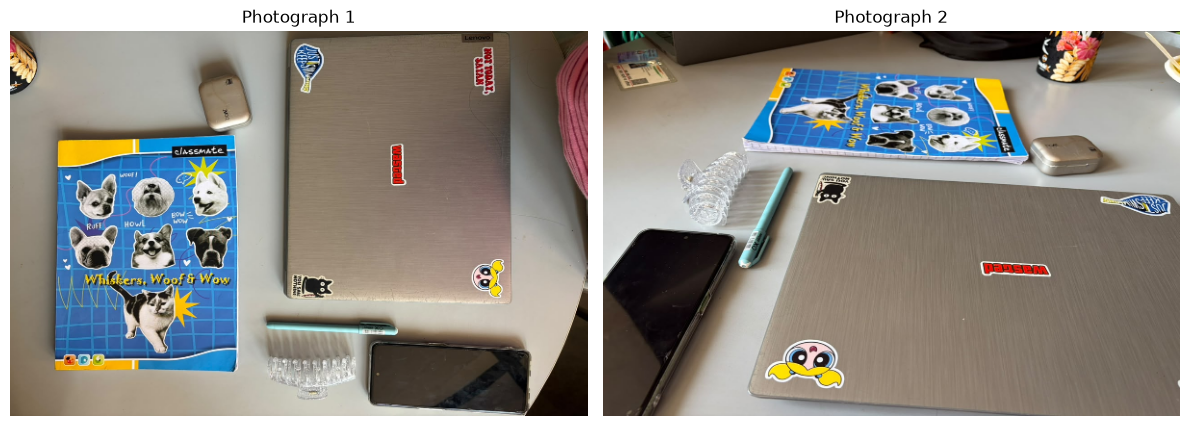

True

In [10]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage.feature import hog
from skimage import exposure

PROJECT_DIR = Path.cwd()
IMAGE_DIR = PROJECT_DIR / "images"
OUTPUT_DIR = PROJECT_DIR / "task2_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

image1_path = IMAGE_DIR / "image1.jpeg"
image2_path = IMAGE_DIR / "image2.jpeg"

if not image1_path.exists() or not image2_path.exists():
    raise FileNotFoundError(
        "Make sure image1.jpeg and image2.jpeg are inside the images folder."
    )

image1_bgr = cv2.imread(str(image1_path))
image2_bgr = cv2.imread(str(image2_path))

if image1_bgr is None or image2_bgr is None:
    raise ValueError("One of the photographs could not be opened.")

image1 = cv2.cvtColor(image1_bgr, cv2.COLOR_BGR2RGB)
image2 = cv2.cvtColor(image2_bgr, cv2.COLOR_BGR2RGB)

image1 = cv2.resize(image1, (600, 400))
image2 = cv2.resize(image2, (600, 400))

gray1 = cv2.cvtColor(image1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(image2, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image1)
plt.title("Photograph 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image2)
plt.title("Photograph 2")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "input_image1.png"),
    cv2.cvtColor(image1, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "input_image2.png"),
    cv2.cvtColor(image2, cv2.COLOR_RGB2BGR)
)

Number of HOG features: 130536


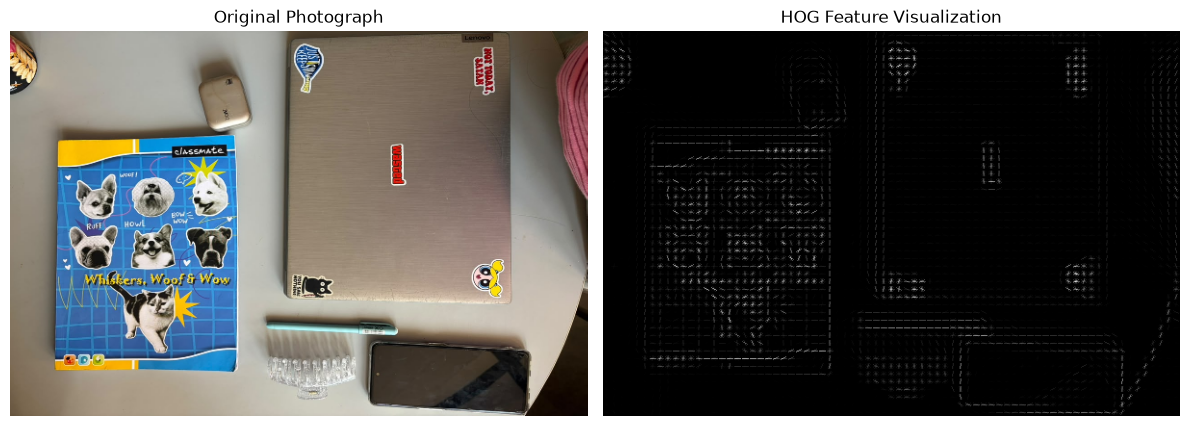

In [11]:
hog_features, hog_image = hog(
    gray1,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
    feature_vector=True
)

hog_visualization = exposure.rescale_intensity(
    hog_image, in_range=(0, np.max(hog_image) if np.max(hog_image) > 0 else 1)
)

print("Number of HOG features:", len(hog_features))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image1)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_visualization, cmap="gray")
plt.title("HOG Feature Visualization")
plt.axis("off")

plt.tight_layout()
plt.show()

plt.imsave(
    str(OUTPUT_DIR / "hog_visualization.png"),
    hog_visualization,
    cmap="gray"
)

np.save(
    OUTPUT_DIR / "hog_features.npy",
    hog_features
)

Image 1 keypoints: 751
Image 2 keypoints: 727
Image 1 descriptor shape: (751, 128)
Image 2 descriptor shape: (727, 128)


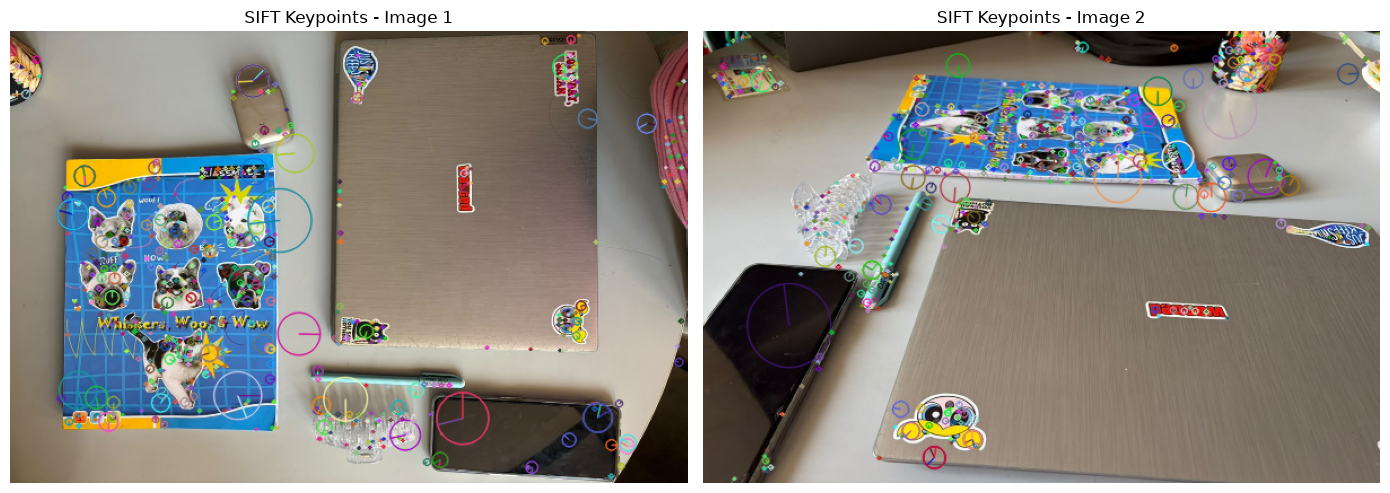

In [12]:
if not hasattr(cv2, "SIFT_create"):
    raise RuntimeError(
        "SIFT is unavailable in this OpenCV installation. Run %pip install --upgrade opencv-python, restart the kernel, and try again."
    )

sift = cv2.SIFT_create()

keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

print("Image 1 keypoints:", len(keypoints1))
print("Image 2 keypoints:", len(keypoints2))

print(
    "Image 1 descriptor shape:",
    descriptors1.shape if descriptors1 is not None else None
)

print(
    "Image 2 descriptor shape:",
    descriptors2.shape if descriptors2 is not None else None
)

keypoints_image1 = cv2.drawKeypoints(
    image1,
    keypoints1,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

keypoints_image2 = cv2.drawKeypoints(
    image2,
    keypoints2,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(keypoints_image1)
plt.title("SIFT Keypoints - Image 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(keypoints_image2)
plt.title("SIFT Keypoints - Image 2")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "sift_keypoints_image1.png"),
    cv2.cvtColor(keypoints_image1, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "sift_keypoints_image2.png"),
    cv2.cvtColor(keypoints_image2, cv2.COLOR_RGB2BGR)
)

if descriptors1 is not None:
    np.save(OUTPUT_DIR / "sift_descriptors_image1.npy", descriptors1)

if descriptors2 is not None:
    np.save(OUTPUT_DIR / "sift_descriptors_image2.npy", descriptors2)

Feature match queries: 751
Good SIFT matches: 31
Matches displayed: 31


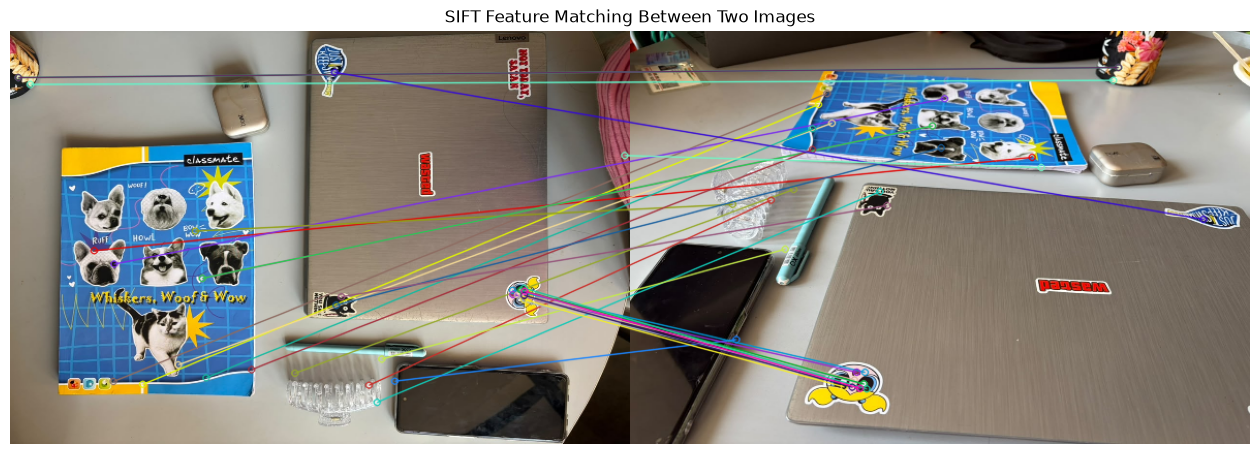

True

In [13]:
def match_sift_features(img_a, img_b):
    kp_a, desc_a = sift.detectAndCompute(img_a, None)
    kp_b, desc_b = sift.detectAndCompute(img_b, None)

    if desc_a is None or desc_b is None or len(desc_a) < 2 or len(desc_b) == 0:
        return kp_a, kp_b, [], 0

    matcher = cv2.BFMatcher(cv2.NORM_L2)
    pairs = matcher.knnMatch(desc_a, desc_b, k=2)

    good_matches = [
        pair[0]
        for pair in pairs
        if len(pair) == 2 and pair[0].distance < 0.75 * pair[1].distance
    ]

    return kp_a, kp_b, good_matches, len(pairs)


kp1, kp2, good_matches, total_match_queries = match_sift_features(
    gray1, gray2
)

matching_image = cv2.drawMatches(
    image1,
    kp1,
    image2,
    kp2,
    good_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

print("Feature match queries:", total_match_queries)
print("Good SIFT matches:", len(good_matches))
print("Matches displayed:", min(50, len(good_matches)))

plt.figure(figsize=(16, 7))
plt.imshow(matching_image)
plt.title("SIFT Feature Matching Between Two Images")
plt.axis("off")
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "sift_feature_matching.png"),
    cv2.cvtColor(matching_image, cv2.COLOR_RGB2BGR)
)

Good matches after 30-degree rotation: 30


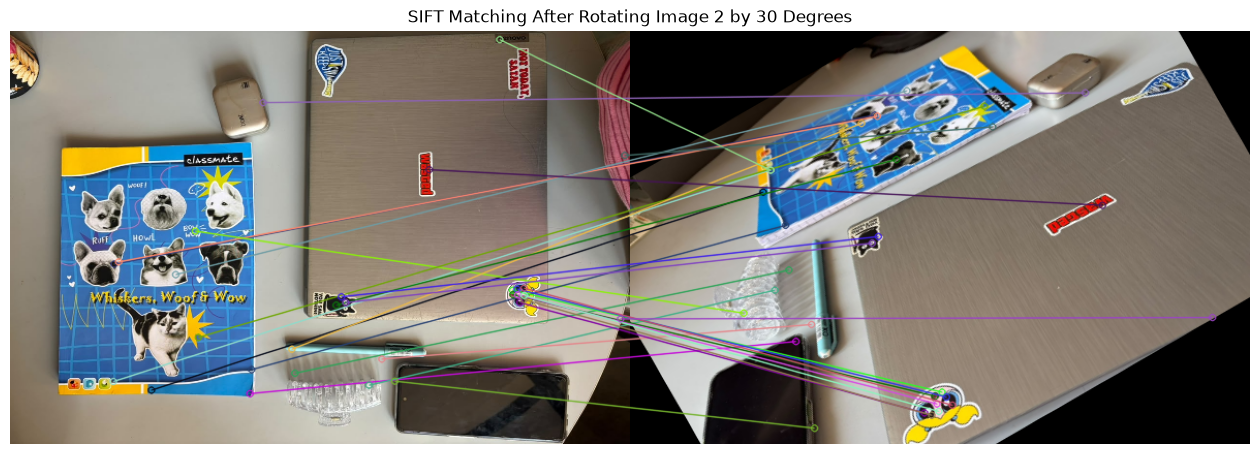

True

In [14]:
height, width = gray2.shape

rotation_matrix = cv2.getRotationMatrix2D(
    (width // 2, height // 2),
    30,
    1.0
)

rotated_image2 = cv2.warpAffine(
    image2,
    rotation_matrix,
    (width, height)
)

rotated_gray2 = cv2.cvtColor(
    rotated_image2, cv2.COLOR_RGB2GRAY
)

kp_original1, kp_rotated2, rotated_matches, _ = match_sift_features(
    gray1, rotated_gray2
)

rotated_matching_image = cv2.drawMatches(
    image1,
    kp_original1,
    rotated_image2,
    kp_rotated2,
    rotated_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

print("Good matches after 30-degree rotation:", len(rotated_matches))

plt.figure(figsize=(16, 7))
plt.imshow(rotated_matching_image)
plt.title("SIFT Matching After Rotating Image 2 by 30 Degrees")
plt.axis("off")
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "sift_matching_rotated.png"),
    cv2.cvtColor(rotated_matching_image, cv2.COLOR_RGB2BGR)
)

Good matches after resizing: 28


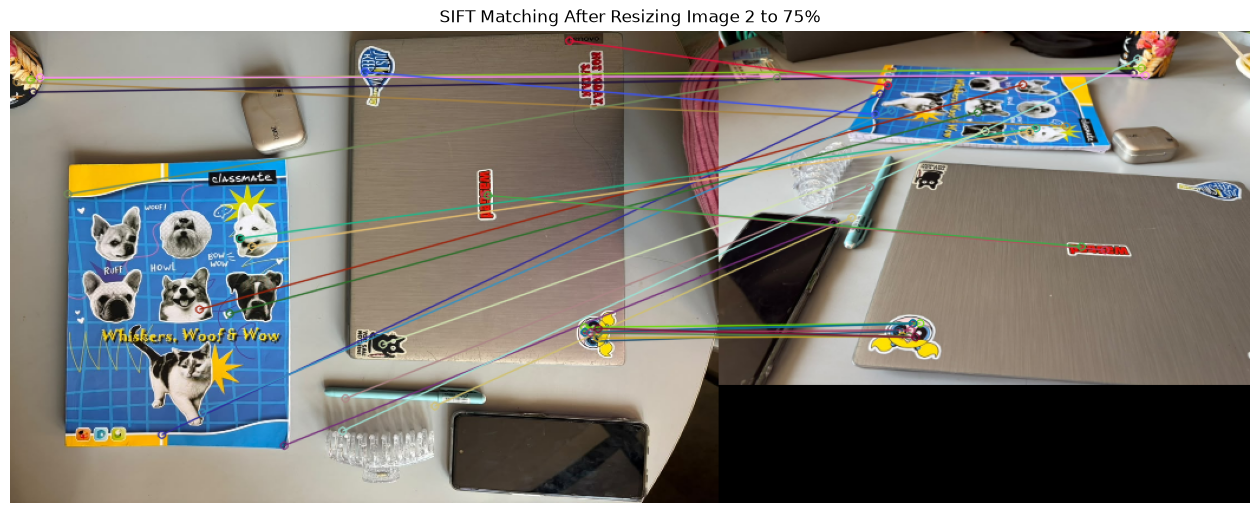

True

In [15]:
resized_image2 = cv2.resize(
    image2,
    None,
    fx=0.75,
    fy=0.75,
    interpolation=cv2.INTER_LINEAR
)

resized_gray2 = cv2.cvtColor(
    resized_image2, cv2.COLOR_RGB2GRAY
)

kp_original1, kp_resized2, resized_matches, _ = match_sift_features(
    gray1, resized_gray2
)

resized_matching_image = cv2.drawMatches(
    image1,
    kp_original1,
    resized_image2,
    kp_resized2,
    resized_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

print("Good matches after resizing:", len(resized_matches))

plt.figure(figsize=(16, 7))
plt.imshow(resized_matching_image)
plt.title("SIFT Matching After Resizing Image 2 to 75%")
plt.axis("off")
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "sift_matching_resized.png"),
    cv2.cvtColor(resized_matching_image, cv2.COLOR_RGB2BGR)
)

In [ ]:
comparison_data = [
    {
        "Experiment": "Original image pair",
        "Good matches": len(good_matches)
    },
    {
        "Experiment": "Image 2 rotated by 30 degrees",
        "Good matches": len(rotated_matches)
    },
    {
        "Experiment": "Image 2 resized to 75%",
        "Good matches": len(resized_matches)
    }
]

comparison_df = pd.DataFrame(comparison_data)

display(comparison_df)

comparison_df.to_csv(
    OUTPUT_DIR / "matching_comparison.csv",
    index=False
)

plt.figure(figsize=(10, 5))
plt.bar(
    comparison_df["Experiment"],
    comparison_df["Good matches"]
)
plt.title("Comparison of SIFT Feature Matching")
plt.xlabel("Experiment")
plt.ylabel("Number of Good Matches")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

,Experiment,Good matches
0,Original image pair,31
1,Image 2 rotated by 30 degrees,30
2,Image 2 resized to 75%,28


In [ ]:
print("TASK 2: FEATURE EXTRACTION AND IMAGE MATCHING")
print("=" * 50)

saved_files = sorted(
    p for p in OUTPUT_DIR.iterdir()
    if p.is_file()
)

for file in saved_files:
    print(file.name)

print("\nTotal output files:", len(saved_files))
print("Output folder:", OUTPUT_DIR.resolve())

## Comparison and Conclusion

HOG features were extracted and visualized, while SIFT detected keypoints and generated descriptors for both photographs. The original image pair produced 31 good matches, the rotated image pair produced 30, and the resized image pair produced 28. These results suggest that SIFT matching remained relatively effective after rotation and resizing, although the number of good matches decreased slightly. Overall, SIFT was useful for matching image features under these transformations.